# Stat 220, Unit 7 Homework: Probability


Much of this is pencil work. Parts marked **by hand** are meant to be done with a pencil before you run anything. The cell that follows a by-hand part computes the same thing exactly, so your number and its number should agree. I would rather you enter in the formula to compute the answer rather than just printing the answer. For example, if the answer is the product of two numbers, please type in the multiplication step and the answer is the output, not the input.

Run the next two cells first.

In [1]:
%pip install -q numpy pandas scipy

In [2]:
import numpy as np
import pandas as pd
from scipy.stats import norm

jobs = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/moving_jobs.csv")
print(jobs.shape)
jobs.head()

(600, 11)


,hours,volume_cuft,crew_size,miles,stairs_flights,packing_service,weekend,est_boxes,dispatcher_rating,quote_source,truck_id
0,7.83,557,3,7.9,1,0,0,37,5,web,T-5
1,10.88,662,2,23.6,2,0,1,51,5,web,T-4
2,16.00,1066,3,3.9,4,0,1,101,2,phone,T-2
3,11.37,845,2,4.7,0,0,0,76,2,referral,T-5
4,7.37,339,3,5.7,2,1,0,21,3,web,T-3


**Problem 1.** *by hand.* Of the 600 moving jobs, each one is either on a weekend or
not, and the customer either bought the packing service or did not. The counts are

| | weekday | weekend | total |
|---|---|---|---|
| **no packing service** | 308 | 119 | 427 |
| **packing service** | 129 | 44 | 173 |
| **total** | 437 | 163 | 600 |

Parts a through d are pencil work.

Part a. Report $\mathbb{P}(\text{packing})$ and $\mathbb{P}(\text{weekend})$, then $\mathbb{P}(\text{packing or weekend})$. Use the addition rule and show the subtraction.

In [3]:
# Your Answer

total = 600

prob_packing = 173 / total
prob_weekend = 163 / total
prob_both = 44 / total

prob_or = prob_packing + prob_weekend - prob_both

print(prob_packing)
print(prob_weekend)
print(prob_or)


0.28833333333333333
0.27166666666666667
0.4866666666666667


Part b. Compute $\mathbb{P}(\text{packing} \mid \text{weekend})$ and $\mathbb{P}(\text{weekend} \mid \text{packing})$.

In [4]:
# Your Answer

prob_packing_given_weekend = 44 / 163
prob_weekend_given_packing = 44 / 173

print(prob_packing_given_weekend)
print(prob_weekend_given_packing)


0.26993865030674846
0.2543352601156069


Part c. Are packing and weekend effectively independent? Support your answer with a calculation.

In [5]:
# Your Answer

print(prob_packing_given_weekend)
print(prob_packing)


0.26993865030674846
0.28833333333333333


_Your answer:_ Yes, they are independent because knowing that it's weekend barely changes the the probability.

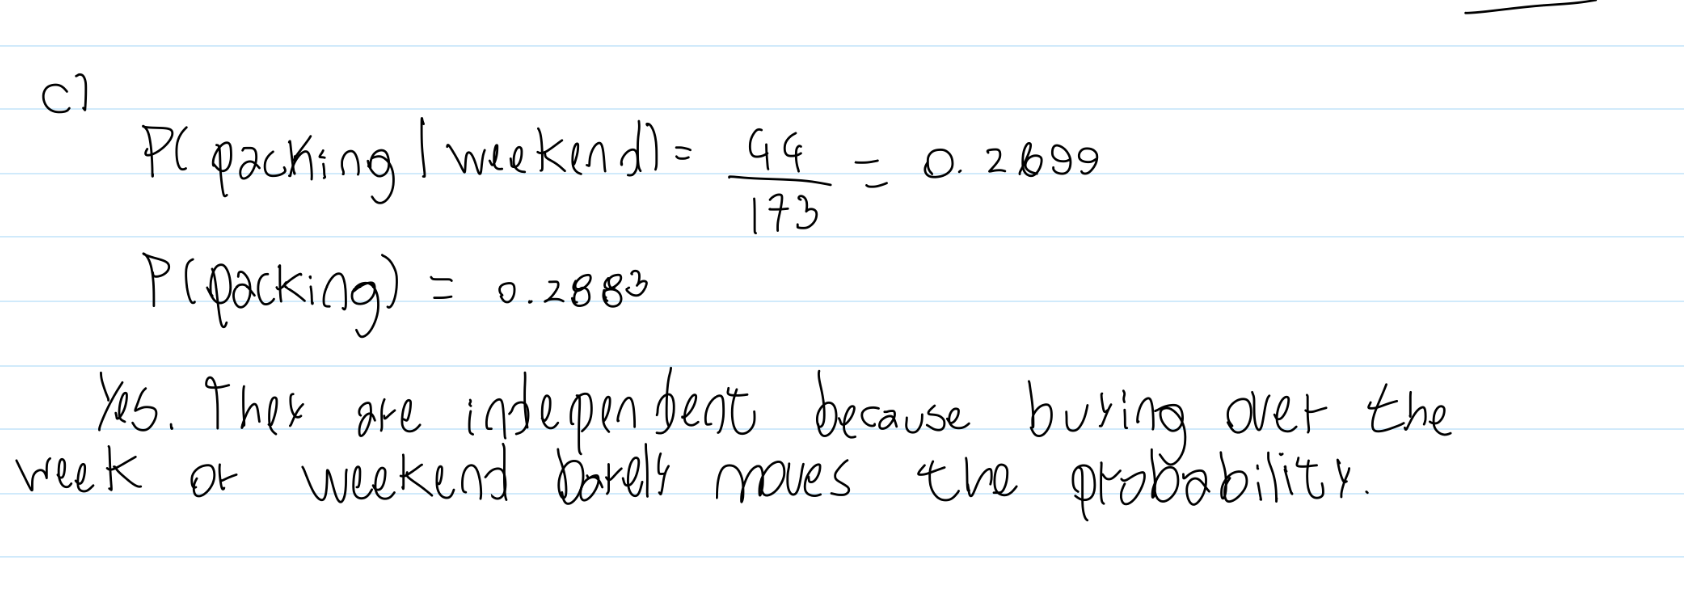

Part d. Every job also records how the quote came in: phone, web or referral, one of the three. Of the 600, 199 came by phone, 194 by web and 207 by referral. A colleague says web and referral must be independent, since one has nothing to do with the other. Use the fact that independence implies that  $\mathbb{P}(\text{web and referral}) = \mathbb{P}(\text{web})\,\mathbb{P}(\text{referral})$ under independence to prove your colleague right or wrong.

In [6]:
# Your Answer

prob_web = 194 / 600
prob_referral = 207 / 600
prob_both = 0

print(prob_web * prob_referral)
print(prob_both)


0.11154999999999998
0


_Your answer:_ My colleague is wrong, they are dependent because 0 is different from 0.1116.

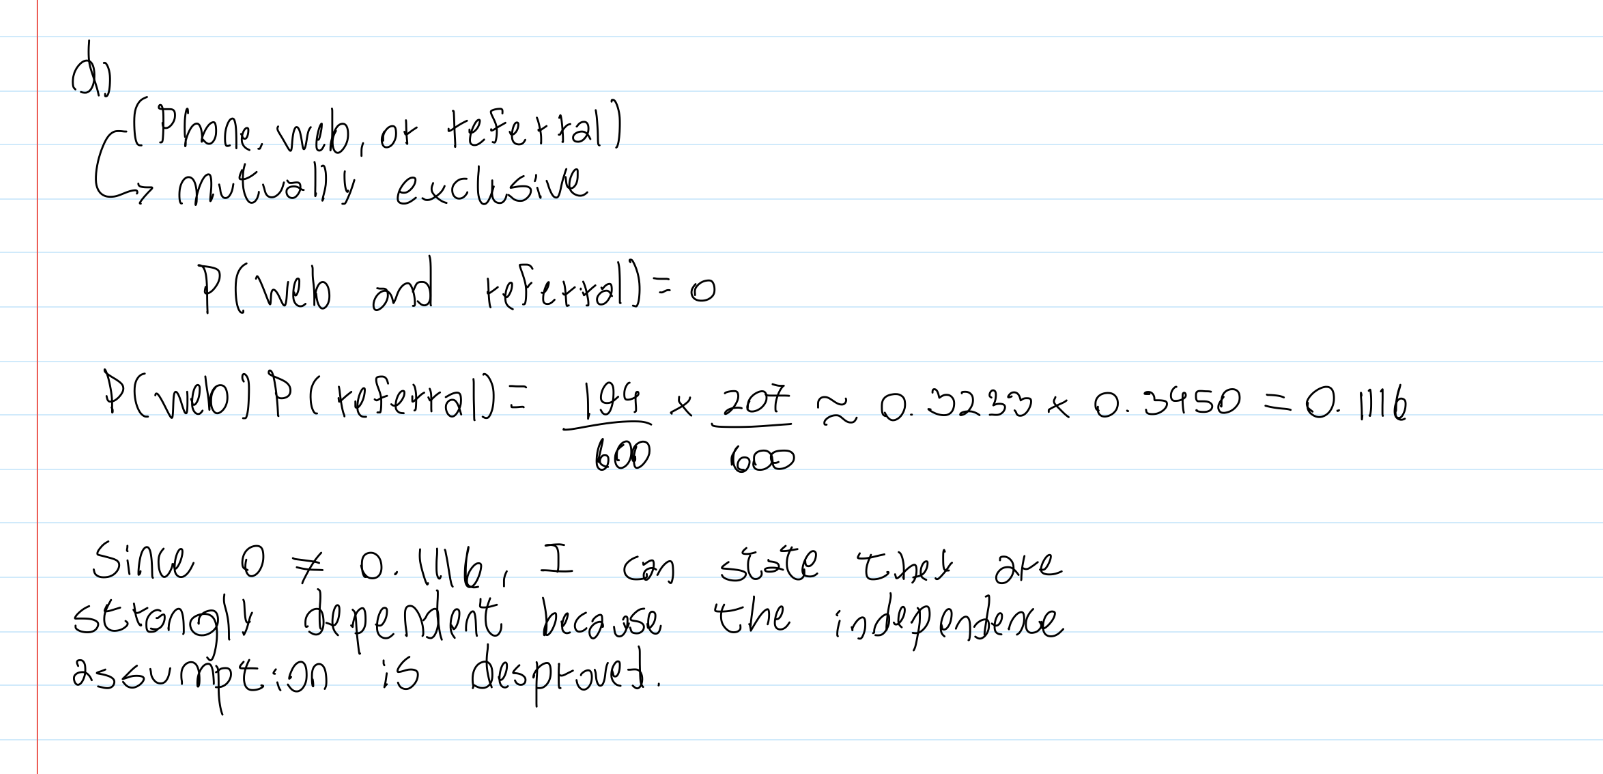

**Problem 2.** *by hand* A shop screens every build with an
automated flaky-test detector. Historically 4% of builds are genuinely flaky. The detector flags
90% of the genuinely flaky builds, and it also flags 15% of the perfectly good ones.

Part a. A build gets flagged. What is the probability it is genuinely flaky?

In [7]:
# Your Answer

prob_flaky = 0.04
prob_good = 0.96

prob_flag_given_flaky = 0.90
prob_flag_given_good = 0.15

prob_flag = (prob_flag_given_flaky * prob_flaky) + (prob_flag_given_good * prob_good)
prob_flaky_given_flag = (prob_flag_given_flaky * prob_flaky) / prob_flag

print(prob_flaky_given_flag)


0.20000000000000004


Part b. The vendor's brochure says "90% accurate." Write the two or three sentences you would say in a meeting to explain why that number does not answer the question anyone in the room is asking.

_Your answer:_ That 90% number is backward.

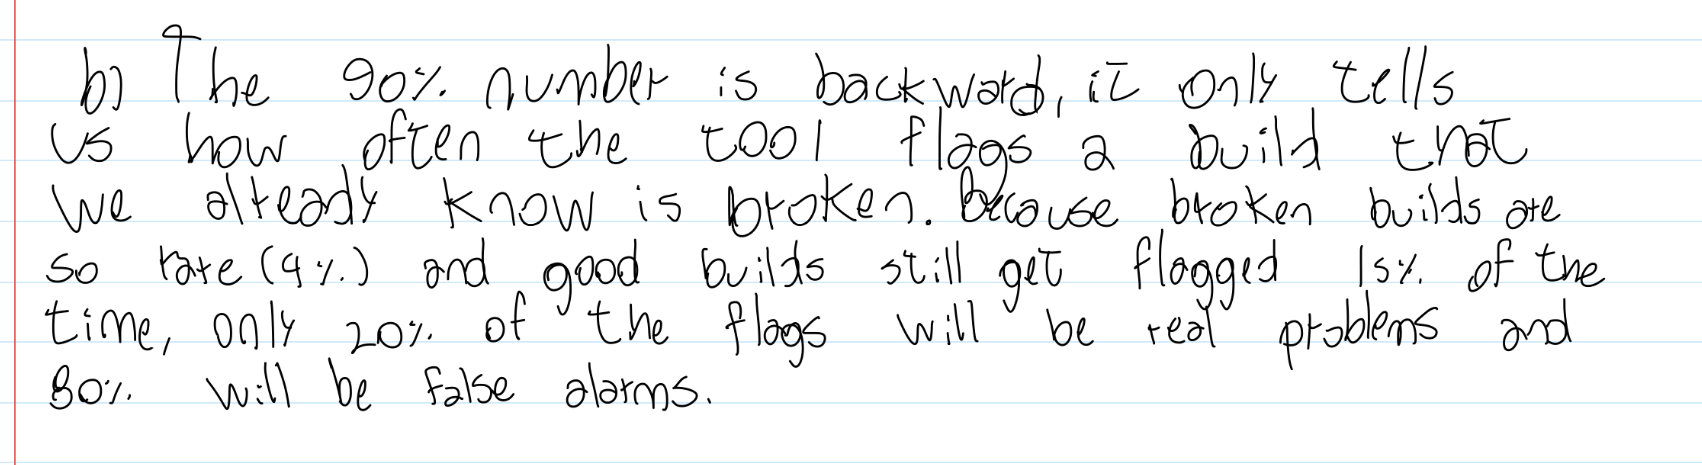

Part c. An engineer can buy exactly one improvement: raise the 90% detection rate to 98%, or cut the 15% false flag rate to 10%. Which one most decreases the probability that a flagged build is a false positive?

In [8]:
# Your Answer

prob_fp_option1 = (0.15 * 0.96) / ((0.98 * 0.04) + (0.15 * 0.96))
prob_fp_option2 = (0.10 * 0.96) / ((0.90 * 0.04) + (0.10 * 0.96))

print(prob_fp_option1)
print(prob_fp_option2)


0.7860262008733625
0.7272727272727273


_Your answer:_ Cutting the false flag rate from 15% to 10% decreases the false positive probability the most.

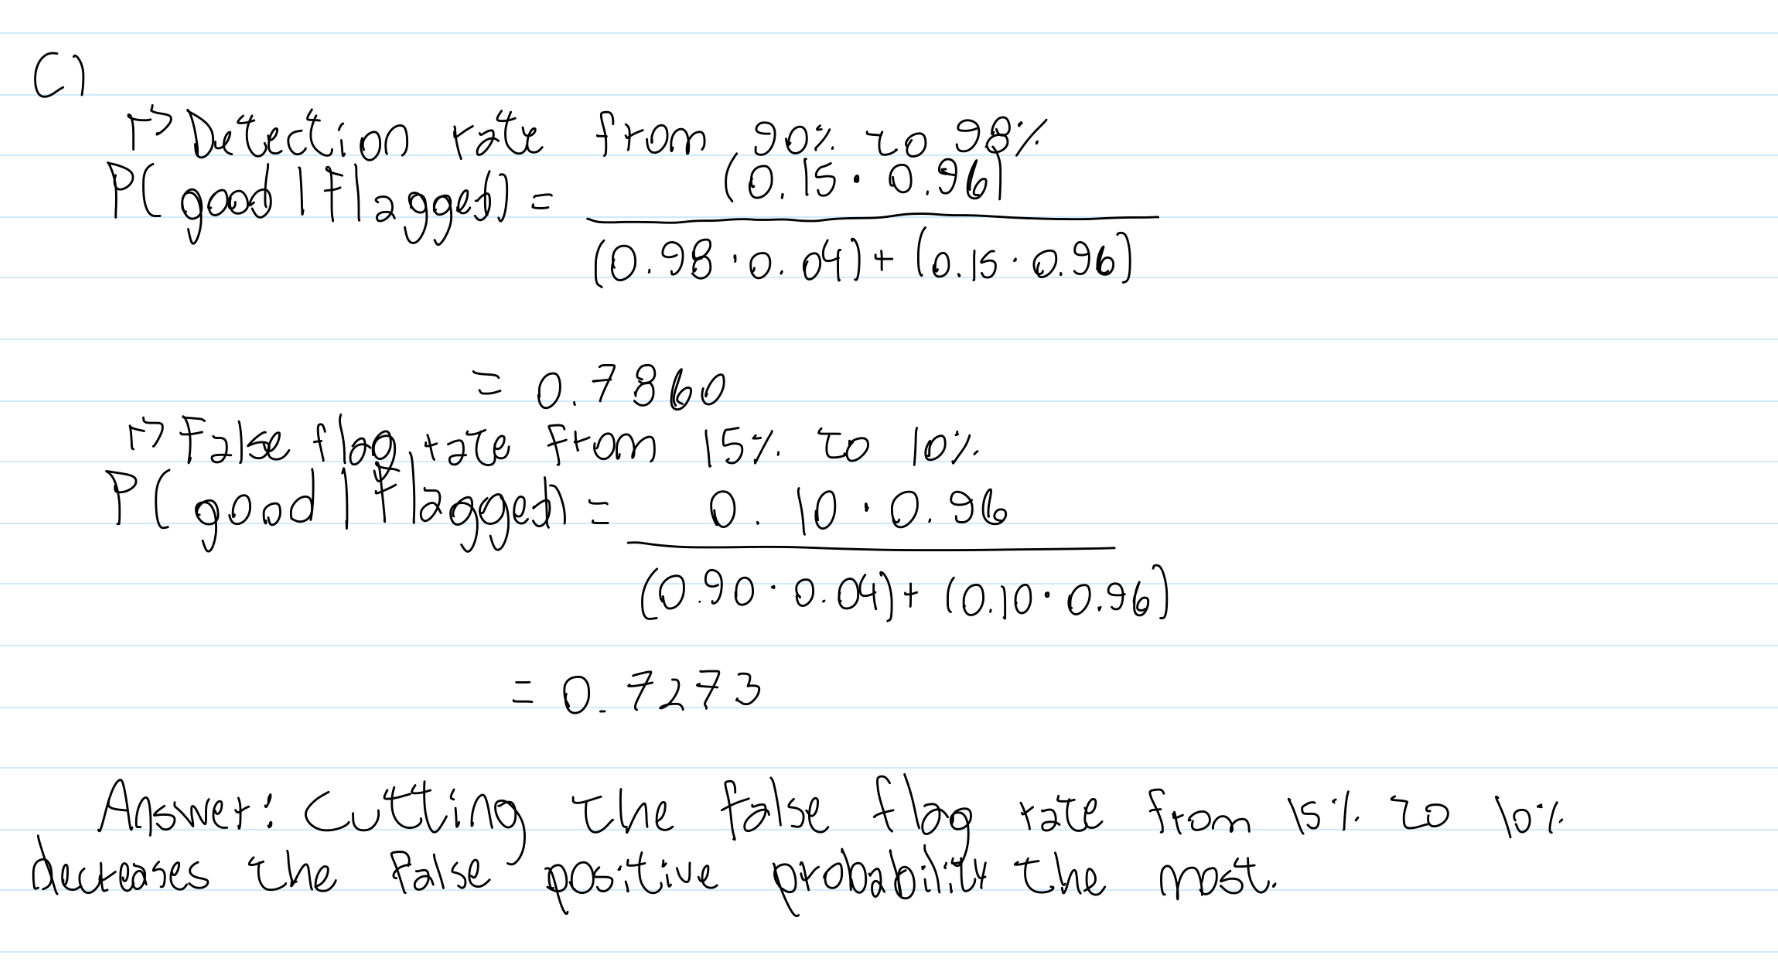




**Problem 3.** A nightly cloud job costs compute credits
according to this table.

| credits | 1 | 2 | 5 | 20 | 100 |
|---|---|---|---|---|---|
| probability | 0.50 | 0.25 | 0.15 | 0.08 | 0.02 |

Part a. **By hand.** Compute $\mathbb{E}[X]$, then $\mathbb{E}[X^2]$, then $\mathrm{Var}(X) = \mathbb{E}[X^2] - (\mathbb{E}[X])^2$, then $\mathrm{SD}(X)$.

In [9]:
# Your Answer

exp_x = (1 * 0.50) + (2 * 0.25) + (5 * 0.15) + (20 * 0.08) + (100 * 0.02)
exp_x2 = (1**2 * 0.50) + (2**2 * 0.25) + (5**2 * 0.15) + (20**2 * 0.08) + (100**2 * 0.02)

var_x = exp_x2 - (exp_x**2)
sd_x = var_x**0.5

print(exp_x)
print(exp_x2)
print(var_x)
print(sd_x)


5.35
237.25
208.6275
14.443943367377207


Answer:

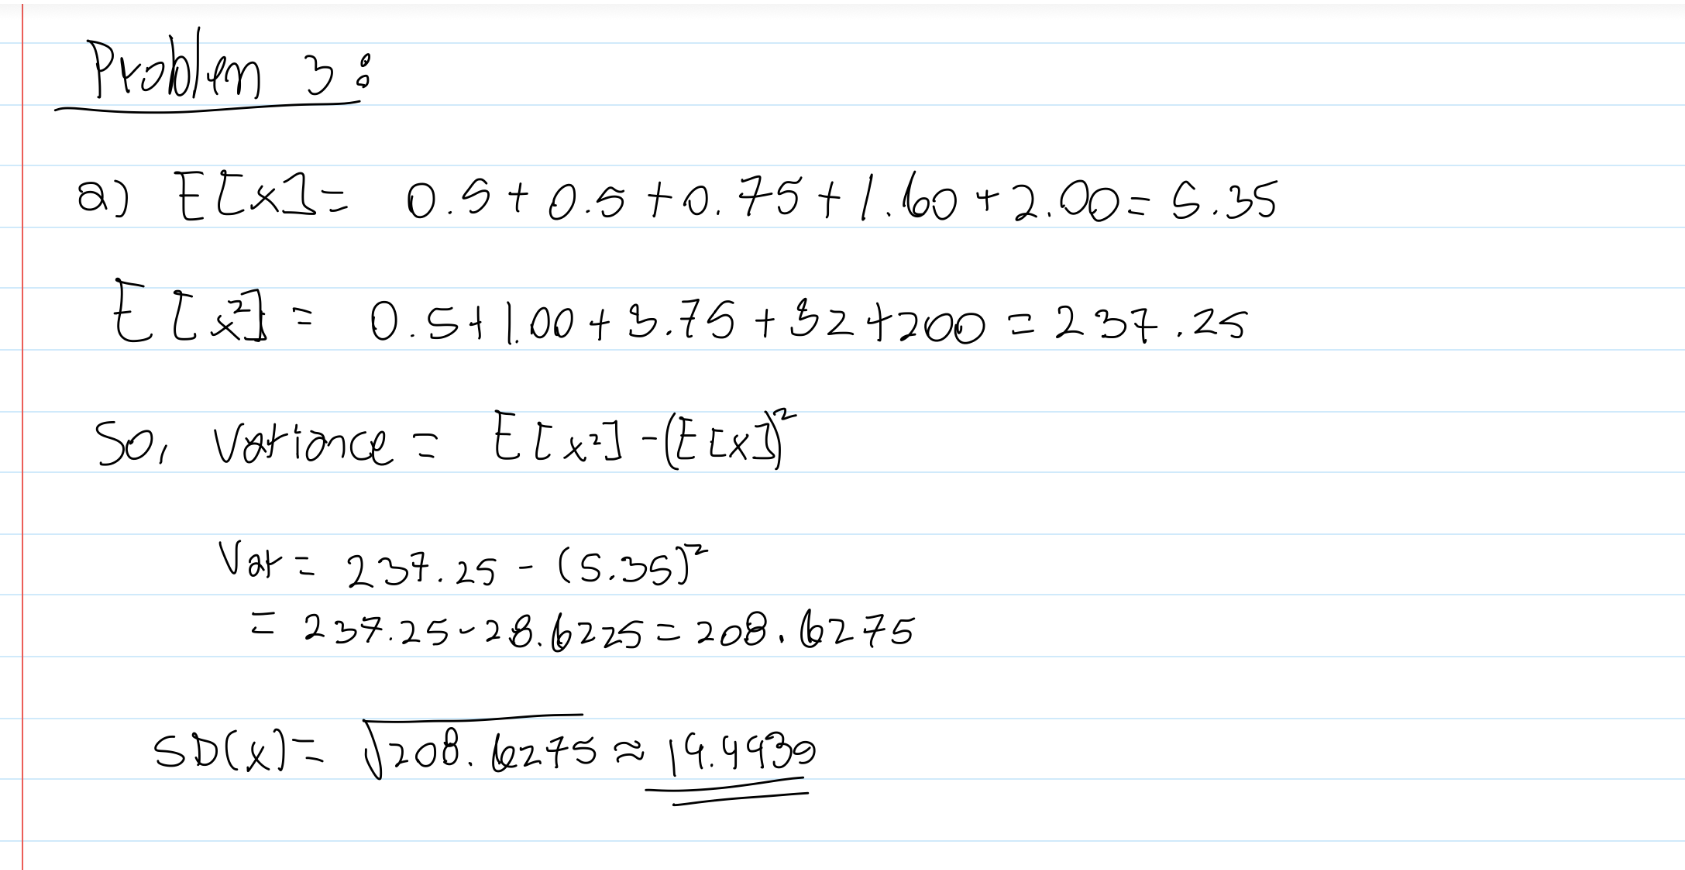

Part b. **By hand.** Report the median of this distribution and compare it to the mean.

In [10]:
# Your Answer
print("1 credit")


0.5


_Your answer:_ Median is 1.

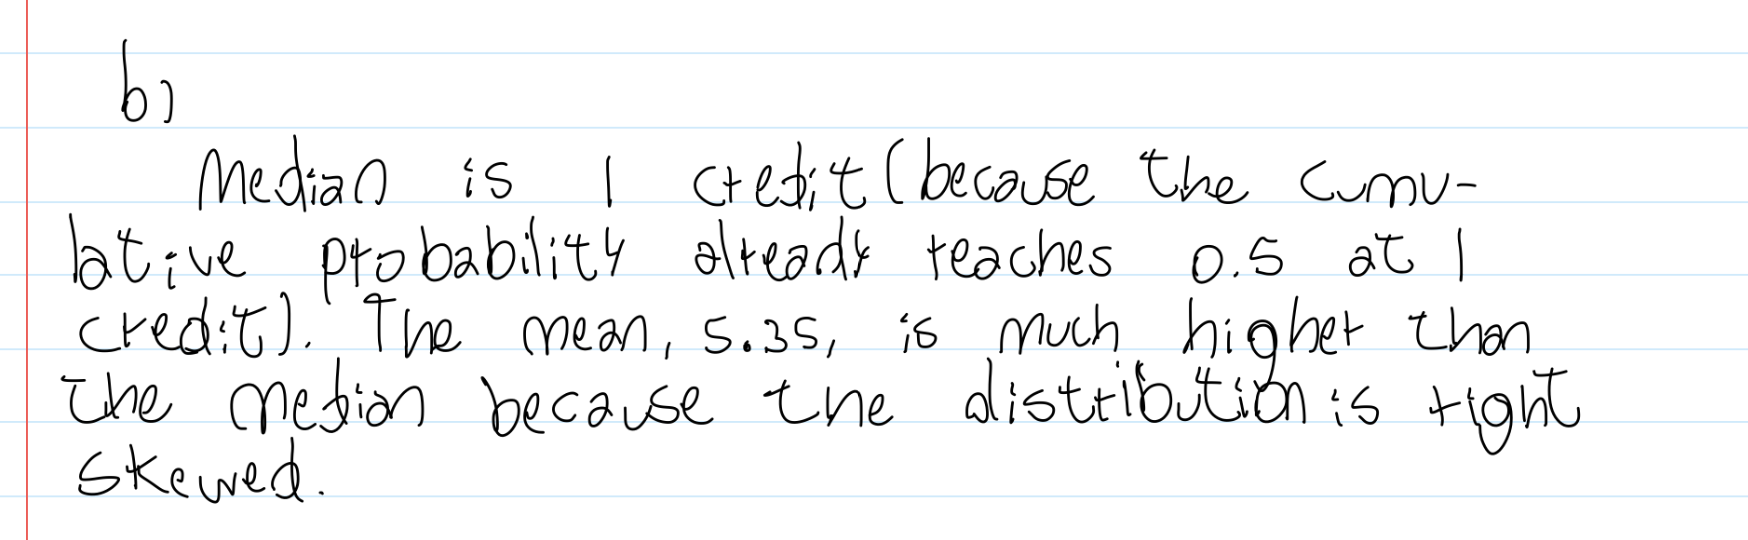



**Problem 4.** Same credit distribution, and your
own $\mathbb{E}[X]$ and $\mathrm{SD}(X)$ from problem 3.

Part a. **By hand.** The provider adds 3 credits of flat overhead and bills at double the metered rate, so the bill is $Y = 3 + 2X$. Give $\mathbb{E}[Y]$ and $\mathrm{SD}(Y)$. Say which of the two the flat 3 changed, which it did not, and why.

In [11]:
# Your Answer

exp_x = 5.35
sd_x = 208.6275**0.5

exp_y = 3 + 2 * exp_x
sd_y = 2 * sd_x

print(exp_y)
print(sd_y)


13.7
28.887886734754414


_Your answer:_

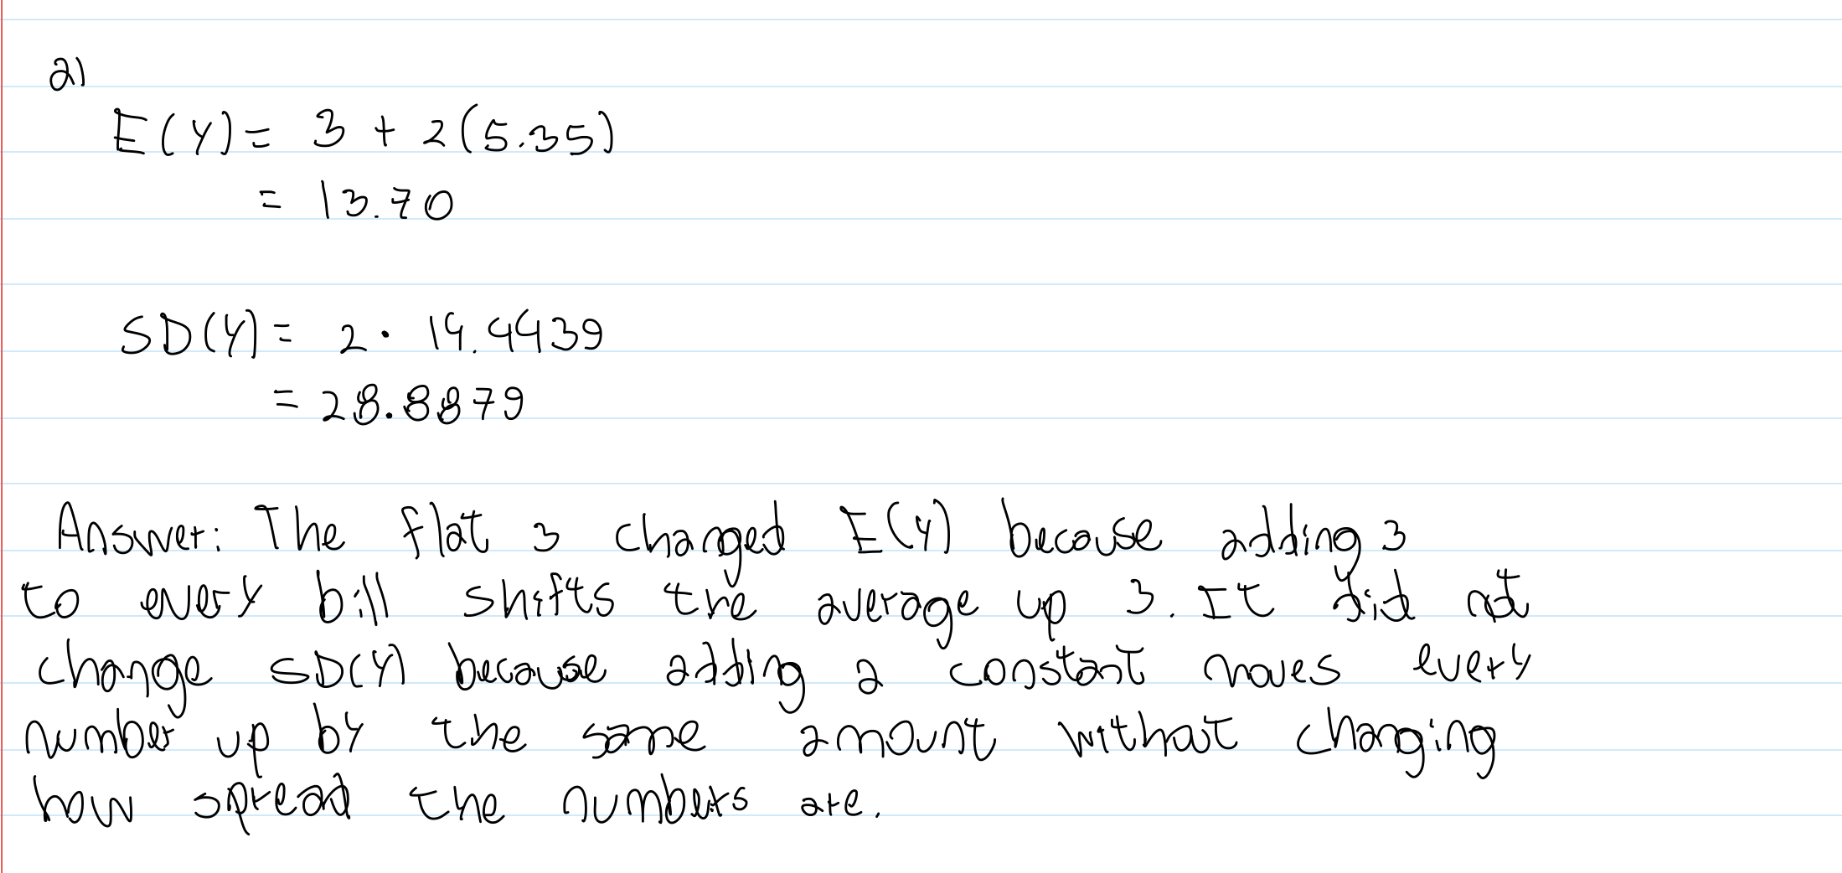

Part b. **By hand.** A support plan caps any single night's bill at 25 credits, so the cost becomes $\min(X, 25)$. Compute $\mathbb{E}[\min(X, 25)]$ directly from the table, by capping each of the five outcomes first and then taking the weighted average.

In [ ]:
# Your Answer

Part c. Compute  $\min(\mathbb{E}[X], 25)$. State why it is not the same as Part b?

In [ ]:
# Your Answer

_Your answer:_

Part d. The support plan costs 1 credit a night. Using your two numbers, is it worth buying with no plan cap (Part a)? Is it worth it with the plan cap (Part b)?

In [ ]:
# Your Answer

_Your answer:_

**Problem 5.**  Still the credit distribution, with
the $\sigma$ you computed in problem 3.

Part a. **By hand.** Ten of these jobs run tonight, independently. Give the mean and the standard deviation of the **total** bill, showing the variance step. Then state what you would have got by adding the ten standard deviations, and by what factor that overstates the spread.

In [ ]:
# Your Answer

_Your answer:_

Part b. **By hand.** Give the standard deviation of the **average** cost per job across those ten jobs, and then across 1,000. Use $\sigma/\sqrt{n}$ and show the division. Say in one sentence why the total's spread grows while the average's shrinks, when both are built from the same jobs.

In [ ]:
# Your Answer

_Your answer:_

Part c. **By hand.** You want the average pinned down to a standard error of 0.5 credits. How many nightly jobs does that take? Solve $\sigma/\sqrt{n} = 0.5$ for $n$.

In [ ]:
# Your Answer

**Problem 6.** *Does the cap pay for itself?* The support plan from problem 4 costs 1 credit
a night and covers whatever a night's bill runs over 25. So what it saves you on one night is

$$W = \max(X - 25,\ 0)$$

which is 75 credits on a 100-credit night and 0 on every other night.

`norm` is already imported: `norm.cdf(z)` returns $\mathbb{P}(Z < z)$ for a standard normal.

Part a. Compute $\mathbb{E}[W]$ and $\mathrm{SD}(W)$ from the five outcomes of $X$.

In [ ]:
# Your Answer

Part b. Over 30 nights the plan costs 30 credits and saves a total of $S = W_1 + \cdots + W_{30}$. Give $\mathbb{E}[S]$ and $\mathrm{SD}(S)$, then use the central limit theorem to approximate $\mathbb{P}(S > 30)$, the chance the plan pays for itself over the month.

In [ ]:
# Your Answer

Part c. Do the same for 100 nights, where the plan costs 100 credits. Report $\mathbb{P}(S > 100)$ and say in one sentence why it is larger than your answer to part b, given that the plan saves 1.50 a night either way.

In [ ]:
# Your Answer

_Your answer:_

Part d. Now run the same approximation for a **single** night: treat $W$ as normal with the mean and standard deviation from part a, and approximate $\mathbb{P}(W > 1)$. Then compute the exact $\mathbb{P}(W > 1)$ straight from the table in problem 3. Report both.

In [ ]:
# Your Answer

Part e. Your two numbers in part d are not close. Explain what went wrong, and state the condition the central limit theorem needs that one night does not meet.

_Your answer:_

**Problem 7.** *Probabilities estimated from data.* Back to the 600 moving jobs. Define two
events:

- $A$: the job took more than 12 hours
- $B$: the job moved more than 800 cubic feet

Estimate each probability below by counting the rows where it holds and dividing by 600. In pandas,
`(jobs.hours > 12).mean()` does the counting and the dividing in one step.

Part a. Estimate $\mathbb{P}(A)$, $\mathbb{P}(B)$ and $\mathbb{P}(A \text{ and } B)$.

In [ ]:
# Your Answer

Part b. Estimate $\mathbb{P}(A \mid B)$ and $\mathbb{P}(B \mid A)$.

In [ ]:
# Your Answer

Part c. Check whether $A$ and $B$ are independent. Report the two numbers you compared, and say what you conclude and why it is the answer you would have expected here.

In [ ]:
# Your Answer

_Your answer:_

Part d. In problem 1 the independence check came out the other way. Explain in two sentences what is different about these two pairs of events.

_Your answer:_